# ДЗ 4 · Генерація та відбір ознак (Тема 10)

**Курс:** Вступ до машинного навчання · **Студентка:** Вох Ірина

**Мета:** порівняти два підходи до оцінки «корисності» ознак набору даних *Autos* для прогнозування ціни автомобіля (`price`):

1. **Взаємна інформація (MI)** між кожною ознакою та цільовою змінною — `mutual_info_regression()`;
2. **Важливість ознак у моделі** (feature importance) ансамблю дерев рішень — `RandomForestRegressor`.

Обидва набори показників уніфікуємо через `.rank(pct=True)`, візуалізуємо grouped barplot (`sns.catplot`) і робимо висновки.

## 0. Імпорт бібліотек

In [1]:
import warnings
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
sns.set_theme()
pd.set_option('display.max_columns', 30)

## 1. Завантаження набору даних Autos

Завантажуємо об'єкт-словник з підготовленими наборами даних так само, як у розділі «Поширені прийоми генерації ознак. Математичні перетворення», і беремо з нього набір `autos`.

In [2]:
with open('../datasets/mod_05_topic_10_various_data.pkl', 'rb') as fl:
    datasets = pickle.load(fl)

autos = datasets['autos']
print(autos.shape)
autos.head()

(193, 25)


,symboling,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,height,curb_weight,engine_type,num_of_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,4,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,4,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,alfa-romero,gas,std,2,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,6,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,audi,gas,std,4,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,4,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,audi,gas,std,4,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,5,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


### 1.1. Короткий огляд даних

Перед відбором ознак перевіримо типи змінних, наявність пропусків і кількість унікальних значень — це потрібно, щоб коректно визначити дискретні ознаки та спосіб кодування.

In [3]:
autos.info()

<class 'pandas.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          193 non-null    int64  
 1   make               193 non-null    object 
 2   fuel_type          193 non-null    object 
 3   aspiration         193 non-null    object 
 4   num_of_doors       193 non-null    int64  
 5   body_style         193 non-null    object 
 6   drive_wheels       193 non-null    object 
 7   engine_location    193 non-null    object 
 8   wheel_base         193 non-null    float64
 9   length             193 non-null    float64
 10  width              193 non-null    float64
 11  height             193 non-null    float64
 12  curb_weight        193 non-null    int64  
 13  engine_type        193 non-null    object 
 14  num_of_cylinders   193 non-null    int64  
 15  engine_size        193 non-null    int64  
 16  fuel_system        193 non-null    ob

In [4]:
print('Пропуски загалом:', autos.isna().sum().sum())
print('Дублікати рядків:', autos.duplicated().sum())

autos.nunique().sort_values().to_frame('n_unique').T

Пропуски загалом: 0
Дублікати рядків: 0


,aspiration,fuel_type,engine_location,num_of_doors,drive_wheels,body_style,engine_type,symboling,num_of_cylinders,fuel_system,peak_rpm,make,city_mpg,highway_mpg,compression_ratio,stroke,bore,engine_size,width,height,wheel_base,horsepower,length,curb_weight,price
n_unique,2,2,2,2,3,5,5,6,6,7,21,21,28,30,31,36,38,40,41,46,50,56,71,165,178


In [5]:
autos.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
symboling,193.0,0.80,1.24,-2.00,0.00,1.00,2.00,3.00
num_of_doors,193.0,3.16,0.99,2.00,2.00,4.00,4.00,4.00
wheel_base,193.0,98.92,6.15,86.60,94.50,97.00,102.40,120.90
length,193.0,174.33,12.48,141.10,166.30,173.20,184.60,208.10
width,193.0,65.89,2.14,60.30,64.10,65.40,66.90,72.00
height,193.0,53.87,2.39,47.80,52.00,54.10,55.70,59.80
curb_weight,193.0,2561.51,526.70,1488.00,2145.00,2414.00,2952.00,4066.00
num_of_cylinders,193.0,4.42,1.02,3.00,4.00,4.00,4.00,12.00
engine_size,193.0,128.12,41.59,61.00,98.00,120.00,146.00,326.00
bore,193.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94


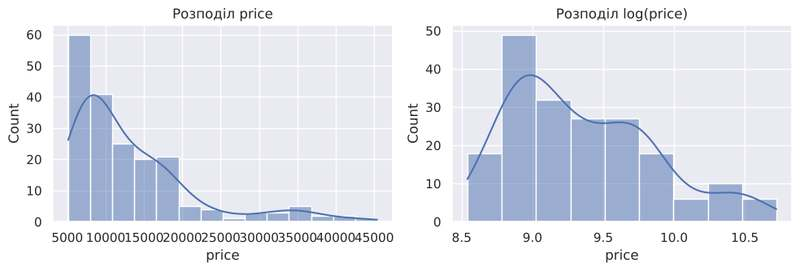

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(autos['price'], kde=True, ax=axs[0])
axs[0].set_title('Розподіл price')
sns.histplot(np.log(autos['price']), kde=True, ax=axs[1])
axs[1].set_title('Розподіл log(price)')
plt.tight_layout()
plt.show()

**Спостереження.** Набір містить 193 автомобілі, 24 вхідні ознаки та ціль `price`; пропусків і дублікатів немає, тому додаткове очищення не потрібне. Цільова змінна має правосторонню асиметрію (кілька дорогих моделей), але для дерев рішень та MI (які інваріантні до монотонних перетворень ознак) це не критично, тому працюємо з `price` у вихідній шкалі.

## 2. Визначення дискретних ознак

`mutual_info_regression()` вимагає явно вказати, які ознаки є **дискретними** (у широкому розумінні):

* усі категоріальні (тип `object`) ознаки — попередньо перетворюємо їх на числові мітки методом `factorize()`;
* цілочислові ознаки, що за своєю природою можуть набувати лише кількох значень: `num_of_doors` (2 або 4 двері) і `num_of_cylinders` (кількість циліндрів).

Інші числові ознаки (розміри, маса, потужність, витрата пального тощо) розглядаємо як неперервні.

In [7]:
X = autos.copy()
y = X.pop('price')

cat_features = X.select_dtypes('object').columns

for colname in cat_features:
    X[colname], _ = X[colname].factorize()

discrete_list = cat_features.to_list() + ['num_of_doors', 'num_of_cylinders']
discrete_mask = X.columns.isin(discrete_list)

print('Категоріальні ознаки:', cat_features.to_list())
print('Усі дискретні ознаки (%d):' % len(discrete_list), discrete_list)
print('Неперервні ознаки (%d):' % (~discrete_mask).sum(), X.columns[~discrete_mask].to_list())

Категоріальні ознаки: ['make', 'fuel_type', 'aspiration', 'body_style', 'drive_wheels', 'engine_location', 'engine_type', 'fuel_system']
Усі дискретні ознаки (10): ['make', 'fuel_type', 'aspiration', 'body_style', 'drive_wheels', 'engine_location', 'engine_type', 'fuel_system', 'num_of_doors', 'num_of_cylinders']
Неперервні ознаки (14): ['symboling', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_size', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg']


## 3. Розрахунок взаємної інформації (MI)

In [8]:
mi_scores = mutual_info_regression(
    X, y,
    discrete_features=discrete_mask,
    random_state=42)

mi_scores = (pd.Series(mi_scores, name='MI Scores', index=X.columns)
             .sort_values())

mi_scores.sort_values(ascending=False).round(4).to_frame().T

,curb_weight,engine_size,horsepower,highway_mpg,city_mpg,width,length,wheel_base,make,bore,fuel_system,stroke,height,num_of_cylinders,drive_wheels,peak_rpm,symboling,compression_ratio,engine_type,aspiration,body_style,fuel_type,engine_location,num_of_doors
MI Scores,0.9132,0.9078,0.884,0.8773,0.7805,0.7049,0.6138,0.5925,0.5438,0.4939,0.4787,0.3722,0.3601,0.3329,0.3325,0.2421,0.2355,0.1722,0.1505,0.0878,0.0805,0.0473,0.0369,0.0114


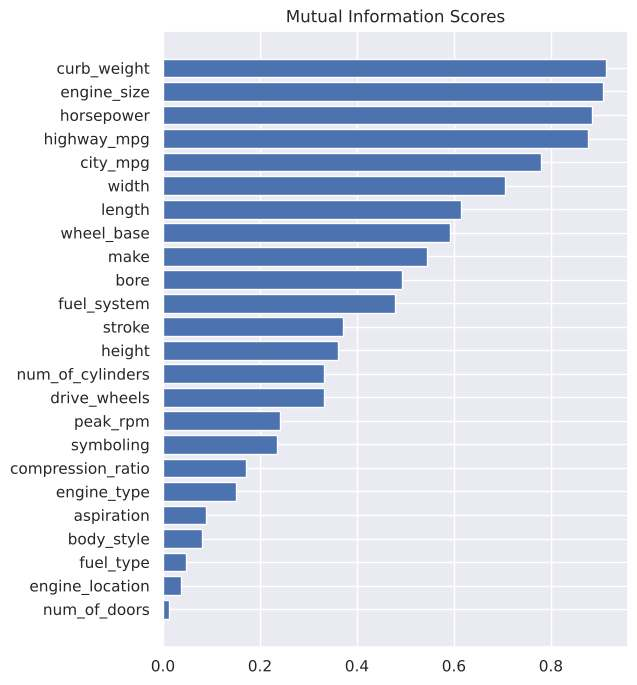

In [9]:
plt.figure(figsize=(6, 8))
plt.barh(np.arange(len(mi_scores)), mi_scores)
plt.yticks(np.arange(len(mi_scores)), mi_scores.index)
plt.title('Mutual Information Scores')
plt.show()

MI-оцінка для неперервних ознак базується на методі k найближчих сусідів, тож вона трохи «шумна». Перевіримо стабільність рейтингу, повторивши розрахунок з різними `random_state`.

In [10]:
mi_runs = pd.DataFrame({
    s: mutual_info_regression(X, y, discrete_features=discrete_mask, random_state=s)
    for s in range(10)}, index=X.columns)

mi_stab = pd.DataFrame({'mean': mi_runs.mean(axis=1), 'std': mi_runs.std(axis=1)})
print('Максимальне std MI між запусками: %.4f' % mi_stab['std'].max())
print('Spearman-кореляція рейтингу (seed=42) із середнім за 10 запусків: %.3f'
      % mi_scores.corr(mi_stab['mean'], method='spearman'))

Максимальне std MI між запусками: 0.0139
Spearman-кореляція рейтингу (seed=42) із середнім за 10 запусків: 0.998


**Висновок по MI.** Найбільше інформації про ціну містять ознаки, що описують «розмір і потужність» автомобіля: `curb_weight`, `engine_size`, `horsepower`, `highway_mpg`, `city_mpg`, `width`, `length`. Найменше — `engine_location`, `fuel_type`, `num_of_doors`, `aspiration`. Рейтинг стабільний щодо випадкового стану оцінювача.

## 4. Регресійна модель і важливість ознак

### 4.1. Кодування категоріальних ознак

Для моделей на основі дерев рішень коректним і зручним є **порядкове (label) кодування** категорій: дерево розбиває ознаку за порогами і не інтерпретує мітки як арифметичні величини, а кожна вихідна ознака лишається **одним стовпцем**. Це важливо для нашої задачі: важливість кожної ознаки в моделі можна напряму зіставити з її MI.

Використовуємо вже закодовану матрицю `X` (мітки з `factorize()`). Додатково (п. 4.5) перевіримо результат на one-hot кодуванні з підсумовуванням важливостей фіктивних змінних.

In [11]:
print(X.dtypes.value_counts())
X[cat_features].head()

int64      17
float64     7
Name: count, dtype: int64


,make,fuel_type,aspiration,body_style,drive_wheels,engine_location,engine_type,fuel_system
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,1,0
3,1,0,0,2,1,0,2,0
4,1,0,0,2,2,0,2,0


### 4.2. Розбиття на навчальну і тестову вибірки

Щоб переконатися, що модель (і, отже, її оцінки важливості) адекватна, оцінюємо її якість на відкладеній вибірці та крос-валідацією.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(154, 24) (39, 24)


### 4.3. Базова модель (baseline) та ансамблі

Порівнюємо `DummyRegressor` (прогноз середньою ціною) з `RandomForestRegressor` і `GradientBoostingRegressor`.

In [13]:
models = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'RandomForest': RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                  max_depth=3, random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv_r2 = cross_val_score(model, X, y, cv=cv, scoring='r2')
    rows.append({'model': name,
                 'R2 test': r2_score(y_test, pred),
                 'MAE test, $': mean_absolute_error(y_test, pred),
                 'MAPE test, %': 100 * mean_absolute_percentage_error(y_test, pred),
                 'R2 CV (mean)': cv_r2.mean(),
                 'R2 CV (std)': cv_r2.std()})

metrics = pd.DataFrame(rows).set_index('model').round(3)
metrics

,R2 test,"MAE test, $","MAPE test, %",R2 CV (mean),R2 CV (std)
model,,,,,
Baseline (mean),-0.003,7527.696,60.640,-0.021,0.029
RandomForest,0.933,1611.750,11.521,0.905,0.054
GradientBoosting,0.943,1432.373,9.706,0.913,0.059


Обидва ансамблі суттєво перевершують базову модель (R² ≈ 0 → R² > 0.9, MAE знижується в кілька разів), тому їхні оцінки важливості ознак можна вважати змістовними. Для подальшого аналізу використовуємо **RandomForestRegressor** (як у темі «Дерева рішень. Важливість ознак в моделі»), навчений на всьому наборі даних — так модель «бачить» той самий обсяг інформації, що й розрахунок MI.

### 4.4. Важливість ознак у моделі (feature importance)

In [14]:
rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
rf.fit(X, y)

fi_scores = (pd.Series(rf.feature_importances_, name='Feature Importance', index=X.columns)
             .sort_values())

print('Сума важливостей: %.3f' % fi_scores.sum())
fi_scores.sort_values(ascending=False).round(4).to_frame().T

Сума важливостей: 1.000


,engine_size,curb_weight,highway_mpg,horsepower,width,make,length,num_of_cylinders,wheel_base,compression_ratio,bore,peak_rpm,stroke,city_mpg,height,body_style,aspiration,fuel_system,drive_wheels,symboling,num_of_doors,fuel_type,engine_type,engine_location
Feature Importance,0.6383,0.2211,0.0319,0.0176,0.0146,0.0144,0.0085,0.0064,0.0064,0.0061,0.0054,0.005,0.0045,0.0045,0.0045,0.0024,0.0018,0.0018,0.0013,0.0011,0.0009,0.0009,0.0005,0.0


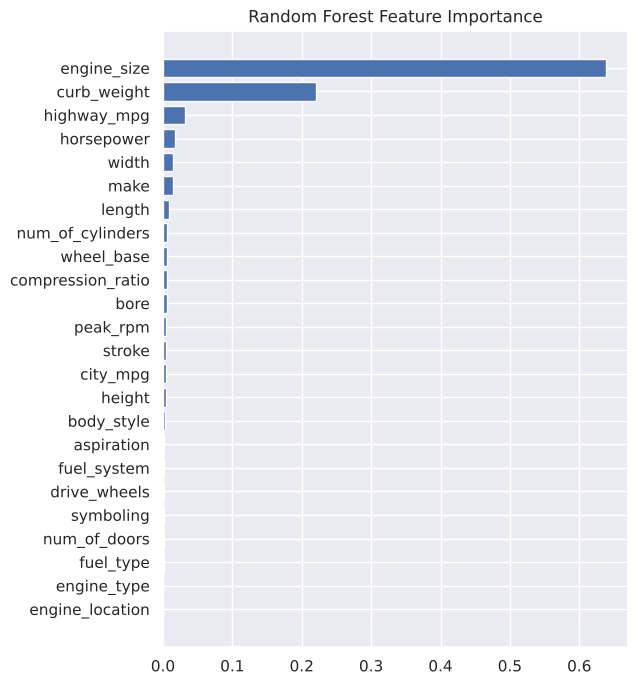

In [15]:
plt.figure(figsize=(6, 8))
plt.barh(np.arange(len(fi_scores)), fi_scores)
plt.yticks(np.arange(len(fi_scores)), fi_scores.index)
plt.title('Random Forest Feature Importance')
plt.show()

### 4.5. Перевірка надійності оцінок важливості

* **One-hot кодування**: важливості фіктивних змінних підсумовуємо назад до вихідної ознаки;
* **Permutation importance** на тестовій вибірці (не має зміщення impurity-важливості на користь ознак з багатьма унікальними значеннями);
* **GradientBoosting** — інший тип ансамблю.

In [16]:
# one-hot варіант
X_ohe = pd.get_dummies(autos.drop(columns='price'), columns=cat_features.to_list(), dtype=int)
rf_ohe = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(X_ohe, y)
fi_ohe_raw = pd.Series(rf_ohe.feature_importances_, index=X_ohe.columns)
orig_name = {c: next((f for f in cat_features if c.startswith(f + '_')), c) for c in X_ohe.columns}
fi_ohe = fi_ohe_raw.groupby(orig_name).sum().reindex(X.columns)

# permutation importance (модель навчена на train, оцінка на test)
rf_tr = models['RandomForest']
perm = permutation_importance(rf_tr, X_test, y_test, n_repeats=30, random_state=42, n_jobs=-1)
pi = pd.Series(perm.importances_mean, index=X.columns)

# gradient boosting
gb = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                               random_state=42).fit(X, y)
fi_gb = pd.Series(gb.feature_importances_, index=X.columns)

check = pd.DataFrame({'RF (label)': fi_scores, 'RF (one-hot, sum)': fi_ohe,
                      'RF permutation': pi, 'GB': fi_gb})
print('Spearman-кореляція рейтингів важливості між варіантами:')
check.corr(method='spearman').round(2)

Spearman-кореляція рейтингів важливості між варіантами:


,RF (label),"RF (one-hot, sum)",RF permutation,GB
RF (label),1.00,0.98,0.82,0.97
"RF (one-hot, sum)",0.98,1.00,0.86,0.95
RF permutation,0.82,0.86,1.00,0.77
GB,0.97,0.95,0.77,1.00


In [17]:
check.sort_values('RF (label)', ascending=False).head(8).round(3)

,RF (label),"RF (one-hot, sum)",RF permutation,GB
engine_size,0.638,0.640,0.528,0.621
curb_weight,0.221,0.219,0.326,0.166
highway_mpg,0.032,0.033,0.007,0.034
horsepower,0.018,0.017,0.008,0.053
width,0.015,0.015,0.005,0.018
make,0.014,0.011,0.014,0.015
length,0.009,0.010,0.002,0.013
num_of_cylinders,0.006,0.006,0.006,0.030


Різні способи кодування й оцінки дають узгоджені рейтинги (висока рангова кореляція), а топ ознак однаковий: `engine_size`, `curb_weight`, `horsepower`, `highway_mpg`. Отже, отримані важливості не є артефактом обраного кодування чи моделі.

## 5. Масштабування / уніфікація показників

MI (у натах, без верхньої межі) та feature importance (частки, що в сумі дають 1) мають різну природу й масштаб. Уніфікуємо їх за допомогою `.rank(pct=True)` — кожне значення замінюється його **процентильним рангом** у межах свого стовпця (0…1]: 1.0 — найкраща ознака, ≈0.04 — найгірша.

In [18]:
scores = pd.concat([mi_scores, fi_scores], axis=1)
scores_rank = scores.rank(pct=True)

scores_rank = scores_rank.sort_values('MI Scores', ascending=False)
scores_rank.round(3)

,MI Scores,Feature Importance
curb_weight,1.000,0.958
engine_size,0.958,1.000
horsepower,0.917,0.875
highway_mpg,0.875,0.917
city_mpg,0.833,0.458
width,0.792,0.833
length,0.750,0.750
wheel_base,0.708,0.667
make,0.667,0.792
bore,0.625,0.583


In [19]:
scores_rank.describe().loc[['min', 'max', 'mean']].round(3)

,MI Scores,Feature Importance
min,0.042,0.042
max,1.000,1.000
mean,0.521,0.521


## 6. Візуалізація: grouped barplot

Переформатовуємо дані у «довгий» формат методом `.melt()` і будуємо згруповані стовпчикові діаграми за допомогою `sns.catplot()`.

In [20]:
scores_long = (scores_rank
               .reset_index(names='feature')
               .melt(id_vars='feature', var_name='metric', value_name='rank_pct'))
scores_long.head()

,feature,metric,rank_pct
0,curb_weight,MI Scores,1.000000
1,engine_size,MI Scores,0.958333
2,horsepower,MI Scores,0.916667
3,highway_mpg,MI Scores,0.875000
4,city_mpg,MI Scores,0.833333


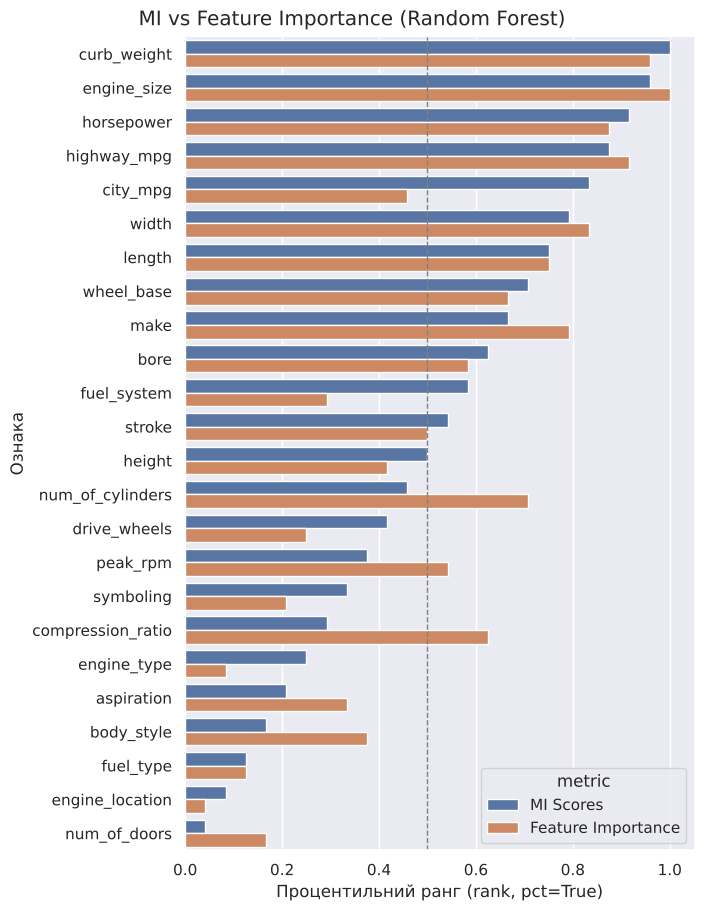

In [21]:
g = sns.catplot(data=scores_long,
                x='rank_pct', y='feature', hue='metric',
                kind='bar', orient='h',
                order=scores_rank.index,
                height=9, aspect=0.8, legend_out=False)
g.set_axis_labels('Процентильний ранг (rank, pct=True)', 'Ознака')
g.figure.suptitle('MI vs Feature Importance (Random Forest)', y=1.01)
g.ax.axvline(0.5, ls='--', c='gray', lw=1)
plt.show()

## 7. Аналіз результатів

In [22]:
rho = scores['MI Scores'].corr(scores['Feature Importance'], method='spearman')
print('Spearman-кореляція між MI і Feature Importance: %.3f' % rho)

diff = (scores_rank['Feature Importance'] - scores_rank['MI Scores']).rename('FI - MI')
analysis = scores_rank.join(diff).sort_values('FI - MI')
analysis.round(3)

Spearman-кореляція між MI і Feature Importance: 0.847


,MI Scores,Feature Importance,FI - MI
city_mpg,0.833,0.458,-0.375
fuel_system,0.583,0.292,-0.292
drive_wheels,0.417,0.250,-0.167
engine_type,0.250,0.083,-0.167
symboling,0.333,0.208,-0.125
height,0.500,0.417,-0.083
wheel_base,0.708,0.667,-0.042
engine_location,0.083,0.042,-0.042
stroke,0.542,0.500,-0.042
bore,0.625,0.583,-0.042


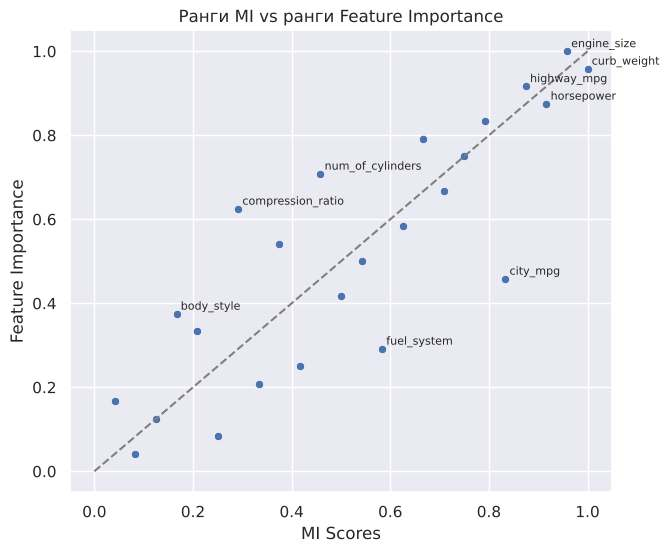

In [23]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=scores_rank, x='MI Scores', y='Feature Importance', ax=ax)
for f, r in scores_rank.iterrows():
    if abs(r['Feature Importance'] - r['MI Scores']) > 0.2 or r['Feature Importance'] > 0.85:
        ax.annotate(f, (r['MI Scores'], r['Feature Importance']), fontsize=8,
                    xytext=(3, 3), textcoords='offset points')
ax.plot([0, 1], [0, 1], ls='--', c='gray')
ax.set_title('Ранги MI vs ранги Feature Importance')
plt.show()

In [24]:
print('Ознаки, значно «важливіші» в моделі, ніж за MI (різниця рангів ≥ 0.2):')
print(analysis[analysis['FI - MI'] >= 0.2].index.to_list())
print('\nОзнаки з високою MI, але малою важливістю в моделі (різниця рангів ≤ -0.2):')
print(analysis[analysis['FI - MI'] <= -0.2].index.to_list())
top5_mi = set(scores_rank['MI Scores'].nlargest(5).index)
top5_fi = set(scores_rank['Feature Importance'].nlargest(5).index)
print('\nСпільні ознаки у топ-5 обох рейтингів:', sorted(top5_mi & top5_fi))

Ознаки, значно «важливіші» в моделі, ніж за MI (різниця рангів ≥ 0.2):
['body_style', 'num_of_cylinders', 'compression_ratio']

Ознаки з високою MI, але малою важливістю в моделі (різниця рангів ≤ -0.2):
['city_mpg', 'fuel_system']

Спільні ознаки у топ-5 обох рейтингів: ['curb_weight', 'engine_size', 'highway_mpg', 'horsepower']


Ранги показують порядок ознак, але приховують **розподіл** «корисності». Порівняємо частки: MI нормуємо на суму (як feature importance) і подивимося, яку частку припадає на топ-2 ознаки.

Частка топ-2 ознак: MI = 17.8%, FI = 85.9%
Кількість ознак, що дають 90% сумарного показника: MI = 16, FI = 4


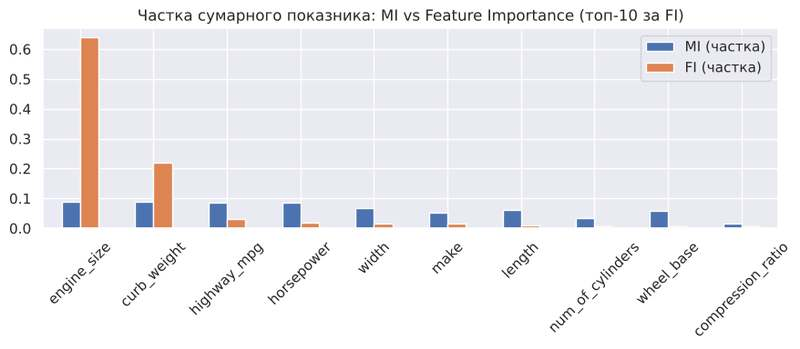

In [25]:
shares = pd.DataFrame({'MI (частка)': mi_scores / mi_scores.sum(),
                       'FI (частка)': fi_scores}).sort_values('FI (частка)', ascending=False)
print('Частка топ-2 ознак: MI = %.1f%%, FI = %.1f%%' % (
    100 * shares['MI (частка)'].nlargest(2).sum(), 100 * shares['FI (частка)'].nlargest(2).sum()))
print('Кількість ознак, що дають 90%% сумарного показника: MI = %d, FI = %d' % (
    (shares['MI (частка)'].sort_values(ascending=False).cumsum() < 0.9).sum() + 1,
    (shares['FI (частка)'].sort_values(ascending=False).cumsum() < 0.9).sum() + 1))

ax = shares.head(10).plot.bar(figsize=(9, 4), rot=45)
ax.set_title('Частка сумарного показника: MI vs Feature Importance (топ-10 за FI)')
plt.tight_layout()
plt.show()

Ілюстрація взаємодії ознак: `fuel_type` має низьку MI, але розділяє дві групи з різною залежністю ціни від потужності (див. навчальний матеріал).

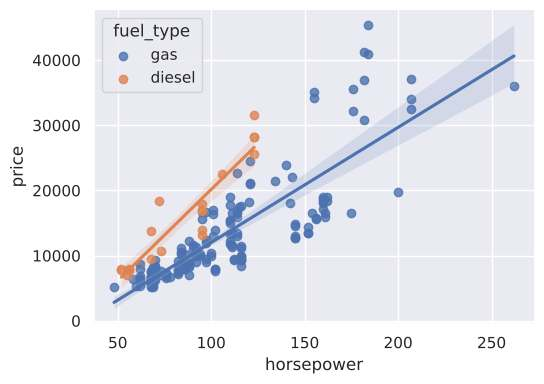

In [26]:
sns.lmplot(data=autos, x='horsepower', y='price', hue='fuel_type',
           facet_kws={'legend_out': False}, height=4, aspect=1.4)
plt.show()

## 8. Висновки

1. **Дискретні ознаки та MI.** До дискретних віднесено 8 категоріальних ознак (після `factorize()`) і цілочислові `num_of_doors`, `num_of_cylinders`; MI розраховано `mutual_info_regression(..., discrete_features=...)`. Найінформативніші щодо `price` — `curb_weight`, `engine_size`, `horsepower`, `highway_mpg`, `city_mpg`; найменш інформативні — `num_of_doors`, `engine_location`, `fuel_type`, `body_style`. Рейтинг MI стабільний (Spearman 0.998 між seed=42 і середнім за 10 запусків).

2. **Модель.** `RandomForestRegressor` з label-кодуванням категорій: R² = 0.933 на тесті та 0.905 у 5-fold CV проти R² ≈ 0 у базової моделі `DummyRegressor`; MAE знижується з ≈7 528 $ до ≈1 612 $ (≈4.7 раза), MAPE — з 60.6 % до 11.5 %. `GradientBoostingRegressor` має близьку якість (R² = 0.943). Рейтинг важливостей підтверджено one-hot кодуванням (ρ = 0.98), градієнтним бустингом (ρ = 0.97) і permutation importance (ρ = 0.82).

3. **Порівняння уніфікованих показників (`.rank(pct=True)`).**
   * **Спільне:** топ-4 обох рейтингів однаковий за складом — `engine_size`, `curb_weight`, `horsepower`, `highway_mpg` (ознаки «розміру/потужності» авто); аутсайдери теж близькі (`engine_location`, `fuel_type`). Загальна рангова кореляція ρ ≈ 0.85.
   * **Розбіжності:** `city_mpg` (MI-ранг 0.83 → FI 0.46) і `fuel_system` (0.58 → 0.29), а також `drive_wheels`, `engine_type` мають помітну MI, але мало важать у моделі: їхня інформація про ціну **дублює** вже використані сильні ознаки (`city_mpg` майже ідентична `highway_mpg`, тип системи живлення пов'язаний з об'ємом двигуна). Навпаки, `compression_ratio` (0.29 → 0.63), `num_of_cylinders` (0.46 → 0.71), `body_style`, `peak_rpm`, `make` у моделі важливіші, ніж за MI: вони корисні **у поєднанні** з іншими ознаками, уточнюючи ціну всередині груп авто схожого розміру/потужності (аналогічно `fuel_type` змінює нахил залежності ціни від потужності — графік вище).
   * **Розподіл «корисності»:** MI розподілена рівномірно (топ-2 ознаки — 17.8 % суми, для 90 % потрібно 16 ознак), а модель концентрує 85.9 % важливості на `engine_size` і `curb_weight` (90 % — лише 4 ознаки). Тобто MI оцінює кожну ознаку **ізольовано**, а модель — **граничний внесок** з урахуванням надлишковості.

4. **Головний висновок (очікуваний результат підтверджено).** «Корисність» окремих ознак з погляду взаємної інформації може значно відрізнятися від їхньої важливості в моделі. MI — швидкий модельно-незалежний інструмент первинного відбору (виявляє і нелінійні зв'язки), але не враховує кореляцію між ознаками та їхні взаємодії; важливість у моделі, навпаки, залежить від моделі й «приховує» корельовані дублікати. Тому відбір ознак варто робити, поєднуючи обидва підходи та знання предметної галузі: наприклад, `city_mpg`/`fuel_system` можна вважати кандидатами на виключення як надлишкові, а `compression_ratio`, `num_of_cylinders`, `fuel_type` не варто відкидати лише через низьку MI.